# Estado del arte: PD de vida completa por supervivencia, riesgos competitivos y satélites macroeconómicos

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 05 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- ubicar los tres peldaños de PD de vida completa del C06 (Kaplan-Meier, un hazard en tiempo discreto con covariables macro, un modelo de Cox) entre los métodos de supervivencia que encontró la investigación, y decir qué métodos no corre el producto;
- mostrar por qué el logit en tiempo discreto y el modelo de Cox dan coeficientes casi iguales cuando el hazard por período es pequeño;
- verificar los signos de los coeficientes macro contra la expectativa económica, como debe hacerlo un validador, y leer qué hace un signo equivocado a la PCE de un escenario;
- comparar los tres peldaños sobre los mismos datos por discriminación, puntaje de Brier integrado y calibración de la PD acumulada, agrupada y para la cosecha de la crisis;
- medir lo que cuesta tratar el prepago como censura frente a una mirada de riesgos competitivos, y leer las trayectorias del factor del satélite macro con su reversión al largo plazo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 a la fecha de reporte 2008-12-31: los préstamos 7(a) a pequeñas empresas de la SBA (Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`) y las formas de escenario 2026 de la Reserva Federal (mirror-allowed). Se leen dos archivos versionados.

- `data/derived/C06/models-rd-2008-12.json`: el ajuste de los tres peldaños (`fit.ladder`: los coeficientes y errores estándar, la línea base de los peldaños de Kaplan-Meier y de Cox), el escalador macro del peldaño de hazard (`model[].details.macro_scaler`), la conversión de un factor (`fit.pit`: la historia del factor sistemático y el satélite) y las definiciones de escenario con sus trayectorias de factor (`fit.scenario_definitions`).
- `data/derived/C06/rd-2008-12.json`: `outputs.rung_comparison` (discriminación, puntaje de Brier integrado y diferencia de calibración a 12 meses de cada peldaño), y las filas de `tests` de la prueba retrospectiva de vida completa por cohorte de origen y peldaño, cuyos `extras` guardan la diferencia de cada horizonte.

Los tres peldaños los ajustó el pipeline (`data-pipeline/pipeline/cases/c06/ladder.py`, con `statsmodels`) sobre los préstamos conocidos a la fecha de reporte; el archivo crudo de préstamos no está versionado, así que este cuaderno **lee los ajustes y las pruebas, y no reajusta**. Todo lo que se recalcula abajo es aritmética sobre números versionados o una llamada al motor sobre ellos.

In [2]:
# Cargar el archivo de modelos y el artefacto de la fecha de reporte y listar los tres peldaños
from riskvalidation.provisions import term_structure as tsm

ROOT = Path("../../..").resolve()
LANG = "es"
models = json.loads((ROOT / "data" / "derived" / "C06" / "models-rd-2008-12.json").read_text(encoding="utf-8"))
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
fit = models["fit"]
ladder = {r["rung_id"]: r for r in fit["ladder"]}

for m_ in models["model"]:
    print(f"{m_['id']:7s} {m_['rung']:22s} | {m_['engine']} {m_['engine_version']} | préstamos: {int(m_['parameters']['n_loans']['value'])} | incumplimientos: {int(m_['parameters']['n_defaults']['value'])}")
print("fecha de corte del entrenamiento:", {k: v["training_cutoff"] for k, v in ladder.items()})
print("artefacto calculado por el motor:", case["provenance"]["riskvalidation_version"], "| motor instalado:", md.version("riskvalidation"))

L0-km   kaplan-meier           | statsmodels 0.15.0 | préstamos: 871618 | incumplimientos: 74139
L1-dth  discrete-time-hazard   | statsmodels 0.15.0 | préstamos: 871618 | incumplimientos: 74139
L2-cox  cox                    | statsmodels 0.15.0 | préstamos: 871618 | incumplimientos: 74139
fecha de corte del entrenamiento: {'L0-km': '2008-12-31', 'L1-dth': '2008-12-31', 'L2-cox': '2008-12-31'}
artefacto calculado por el motor: 0.5.0 | motor instalado: 0.8.1


## Método

Los tres peldaños modelan el tiempo desde la fecha de reporte hasta el incumplimiento, con el prepago como censura, y dan la PD acumulada $F(t)$ que el cuaderno 01 convierte en una PCE. Difieren en cómo dejan que el hazard dependa del préstamo y de la macroeconomía.

**L0, Kaplan-Meier.** Una curva agrupada por edad del préstamo. El estimador producto-límite de la supervivencia es $\hat S(t) = \prod_{t_i \le t}\bigl(1 - d_i/n_i\bigr)$, con $d_i$ los incumplimientos y $n_i$ los préstamos en riesgo a la edad $t_i$. No tiene covariables ni macroeconomía, así que su orden es solo el orden por edad.

**L1, hazard en tiempo discreto con covariables macro.** Una regresión logística sobre registros préstamo-período (Shumway, 2001; Botha y Verster, 2025):

$$\mathrm{logit}\,h_i(t) = \alpha(a_{it}) + \boldsymbol\beta^\top \mathbf{x}_i + \boldsymbol\gamma^\top \mathbf{m}_{t-\ell}$$

con $\alpha$ una función escalonada de la edad del préstamo (bandas de edad), $\mathbf{x}_i$ las covariables del préstamo (tamaño, plazo, sector, rotativo) y $\mathbf{m}_{t-\ell}$ las variables macro rezagadas $\ell = 1$ trimestre, estandarizadas. Es el peldaño que lleva los escenarios.

**L2, riesgos proporcionales de Cox** (Cox, 1972): $h_i(t) = h_0(t)\exp(\boldsymbol\beta^\top \mathbf{x}_i)$, con la edad del préstamo como escala de tiempo y empates de Breslow. La implementación de `statsmodels` que usa el pipeline no tiene covariables que varíen en el tiempo, así que este peldaño **no tiene macroeconomía** y no puede llevar un escenario.

Para un hazard por período pequeño $h$, $\mathrm{logit}\,h = \log\bigl(h/(1-h)\bigr) \approx \log h$, así que los coeficientes de L1 y L2 en las covariables comunes deberían coincidir. La macroeconomía entra a la estructura de plazos solo en L1.

**La validación de un peldaño** es la prueba retrospectiva de vida completa del cuaderno 05 y la comparación de peldaños: la concordancia de Harrell (la probabilidad de que, de dos préstamos, el de menor supervivencia tenga el mayor riesgo previsto, con empates como un medio), el puntaje de Brier integrado de la predicción de supervivencia y la diferencia de calibración a 12 meses entre la PD acumulada prevista y la observada. La mirada de un factor (BCBS 2005; Gordy 2003) vincula la macroeconomía con la PD mediante un factor sistemático $z$ que un satélite regresa sobre variables macro; los pesos de los pronósticos de corto plazo decaen hacia valores de largo plazo (carta del BCE del 1 de abril de 2020).

## Estado del arte

La investigación (dossiers 02 y 04) encontró los métodos siguientes para la estructura de plazos del incumplimiento bajo IFRS 9. La última columna dice qué hace el producto con cada uno.

| Método | Qué agrega | Fuente | En Contraste |
|---|---|---|---|
| Kaplan-Meier y curvas de cosecha | el incumplimiento acumulado agrupado y por cohorte, con censura | Botha y Verster 2025 | peldaño L0, leído aquí |
| Hazard en tiempo discreto (logit persona-período) con covariables macro | PD de vida completa bajo un escenario macro, con un vector macro rezagado | Shumway 2001; Botha y Verster 2025 | peldaño L1, leído aquí |
| Riesgos proporcionales de Cox, con o sin covariables que varían en el tiempo | efectos de covariables sin supuesto de línea base; macro que varía en el tiempo | Cox 1972 | peldaño L2 (sin covariables que varíen en el tiempo), leído aquí |
| Riesgos competitivos, por causa o Fine-Gray | incidencia de incumplimiento cuando el prepago es una salida competitiva | Fine y Gray 1999; Botha y Verster 2025 | `competing_risks` del motor; el C06 trata el prepago como censura (hallazgo `F-PREPAYMENT`) |
| Descomposición edad-período-cohorte | ciclo de vida, calidad de la cosecha y entorno en un solo logit | Breeden 2016 | no se corre |
| Modelos multiestado y de tasas de transición | transiciones entre estados de mora con insumos macro | Botha, Verster y Breedt 2025 | no se corre |
| Mixture cure, bosques de supervivencia, supervivencia profunda | una fracción curada; efectos no lineales | la investigación, dossier 04 (peldaños S4 a S6) | no se corre |
| Satélite macro con reversión a la media | trayectorias de escenario de un factor sistemático que revierten al largo plazo | carta del BCE del 1 de abril de 2020; Botha y Verster 2025 | el satélite de un factor de `fit.pit`, leído aquí |

Los paquetes que necesitan esos últimos peldaños (`lifelines`, `scikit-survival`, `pycox`) no son pines del pipeline ni del entorno de cuadernos, así que **NO ESTÁ VERIFICADO** que Contraste corra alguno: este cuaderno compara solo los tres peldaños que el C06 versionó. Las métricas de validación de la investigación para modelos de supervivencia (concordancia de Harrell y de Uno, AUC dependiente del tiempo, puntaje de Brier integrado, y calibración de la PD acumulada por decil en horizontes fijos contra el estimador de Kaplan-Meier o de Aalen-Johansen) son las que usa la comparación de peldaños; la comparación versionada reporta la concordancia, el puntaje de Brier integrado y la diferencia de calibración a 12 meses.

### Paso 1: los coeficientes de L1 y L2 en las covariables comunes

Ambos peldaños tienen las covariables del préstamo: tres bandas de tamaño, tres de plazo, once grupos de sector y la marca de rotativo. La celda alinea los 18 coeficientes que ambos ajustan, imprime algunos y mide qué tan cerca están los dos conjuntos: la mayor diferencia absoluta y la correlación. Los de L1 están en escala logit y los de L2 en escala log-hazard, y se espera que coincidan cuando el hazard por período es pequeño.

In [3]:
# Alinear los coeficientes que comparten el hazard en tiempo discreto y el modelo de Cox y compararlos
dth = {c["name"]: c for c in ladder["L1-dth"]["coefficients"]}
cox = {c["name"]: c for c in ladder["L2-cox"]["coefficients"]}
common = [name for name in cox if name in dth]
a = np.array([dth[n]["estimate"] for n in common])
b = np.array([cox[n]["estimate"] for n in common])
print("covariables comunes:", len(common), "| solo en el peldaño de hazard (bandas de edad, macro, constante):", len(dth) - len(common))
for n in ("term_over_240", "term_61_120", "revolver", "sector_accommodation-food", "size_over_350k"):
    print(f"{n:28s} L1: {dth[n]['estimate']:+.4f} | L2: {cox[n]['estimate']:+.4f} | diferencia: {dth[n]['estimate'] - cox[n]['estimate']:+.4f}")
print("mayor diferencia absoluta:", round(float(np.abs(a - b).max()), 4), "| correlación:", round(float(np.corrcoef(a, b)[0, 1]), 5))
print("mayor diferencia en unidades del error estándar de L1:", round(float(np.max(np.abs(a - b) / np.array([dth[n]["std_error"] for n in common]))), 2))

covariables comunes: 18 | solo en el peldaño de hazard (bandas de edad, macro, constante): 12
term_over_240                L1: -2.4475 | L2: -2.4413 | diferencia: -0.0062
term_61_120                  L1: -1.0719 | L2: -1.0559 | diferencia: -0.0159
revolver                     L1: +0.5083 | L2: +0.5436 | diferencia: -0.0353
sector_accommodation-food    L1: +0.6726 | L2: +0.6336 | diferencia: +0.0389
size_over_350k               L1: +0.0641 | L2: +0.0629 | diferencia: +0.0012
mayor diferencia absoluta: 0.0389 | correlación: 0.9998
mayor diferencia en unidades del error estándar de L1: 3.2


### Paso 2: los coeficientes macro y sus signos

Solo L1 tiene covariables macro, estandarizadas con la media y la desviación estándar del escalador macro. Un validador verifica cada signo contra la expectativa económica: una mayor tasa de desempleo y una mayor tasa prime deberían subir el hazard, un mayor crecimiento del PIB real debería bajarlo (IFRS 9 B5.5.52 pide que los cambios de la PCE sean consistentes en dirección con los datos; BCBS d350 36(d) pide probar retrospectivamente los factores). Las expectativas son las **declaradas** de esta lección. La celda imprime, para cada variable, la estimación, su error estándar, el estadístico $z$ $\hat\gamma/\mathrm{ee}$, la razón de riesgo por desviación estándar $e^{\hat\gamma}$ (en escala de odds) y si el signo es el esperado.

In [4]:
# Leer los coeficientes macro del peldaño de hazard y verificar sus signos contra la expectativa declarada
EXPECTED_SIGN = {"unemployment_rate": +1, "real_gdp_growth": -1, "prime_rate": +1}  # expectativa declarada de la lección
scaler = [m_ for m_ in models["model"] if m_["id"] == "L1-dth"][0]["details"]["macro_scaler"]
for name, sign in EXPECTED_SIGN.items():
    c = dth[name]
    z = c["estimate"] / c["std_error"]
    ok = np.sign(c["estimate"]) == sign
    print(f"{name:18s} media y desviación del escalador: {scaler[name][0]:.3f} {scaler[name][1]:.3f} | estimación: {c['estimate']:+.4f} | error est.: {c['std_error']:.4f} | z: {z:+.2f} | exp: {np.exp(c['estimate']):.3f} | signo esperado: {si_no(ok)}")
print("el hallazgo que versiona el artefacto:", [f["title"][LANG] for f in case["findings"] if f["id"] == "F-SCENARIO-ORDER"][0])

unemployment_rate  media y desviación del escalador: 5.441 0.966 | estimación: -0.0534 | error est.: 0.0089 | z: -5.99 | exp: 0.948 | signo esperado: no
real_gdp_growth    media y desviación del escalador: 2.873 2.239 | estimación: -0.1920 | error est.: 0.0039 | z: -49.11 | exp: 0.825 | signo esperado: sí
prime_rate         media y desviación del escalador: 7.147 1.685 | estimación: +0.1138 | error est.: 0.0060 | z: +18.86 | exp: 1.120 | signo esperado: sí
el hallazgo que versiona el artefacto: El escenario severamente adverso da una PCE menor que el base: las sensibilidades macro del hazard tienen el signo equivocado en esta fecha


### Paso 3: los tres peldaños sobre los mismos datos

La comparación de peldaños del artefacto reporta, para cada peldaño, el índice de concordancia, el puntaje de Brier integrado y la diferencia entre la PD acumulada prevista y la observada a 12 meses. El peldaño de Kaplan-Meier es una curva agrupada por edad, así que no reporta concordancia (su orden es el orden por edad) y el artefacto da la razón solo en inglés. La celda imprime la tabla y el peldaño que gana cada columna.

In [5]:
# Imprimir la comparación de peldaños y el ganador de cada columna
comparison = {r["rung_id"]: r for r in case["outputs"]["rung_comparison"]}
print(f"{'':8s} {'c-index':>10s} {'Brier integrado':>18s} {'diferencia a 12 meses':>22s}")
for rung, r in comparison.items():
    c_index = "-" if r["c_index"] is None else f"{r['c_index']:.4f}"
    print(f"{rung:8s} {c_index:>10s} {r['integrated_brier']:18.4f} {r['calibration_gap_12m']:22.4f}")
with_c = {k: r["c_index"] for k, r in comparison.items() if r["c_index"] is not None}
print("mejor concordancia:", max(with_c, key=with_c.get), "| mejor Brier integrado:", min(comparison, key=lambda k: comparison[k]["integrated_brier"]), "| menor diferencia a 12 meses:", min(comparison, key=lambda k: comparison[k]["calibration_gap_12m"]))
print("dispersión del Brier integrado de los tres peldaños bajo 1e-3:", si_no(max(r["integrated_brier"] for r in comparison.values()) - min(r["integrated_brier"] for r in comparison.values()) < 0.001))

            c-index    Brier integrado  diferencia a 12 meses
L0-km             -             0.0615                 0.0118
L1-dth       0.6106             0.0606                 0.0025
L2-cox       0.5903             0.0615                 0.0141
mejor concordancia: L1-dth | mejor Brier integrado: L1-dth | menor diferencia a 12 meses: L1-dth
dispersión del Brier integrado de los tres peldaños bajo 1e-3: sí


### Paso 4: calibración de la PD acumulada, agrupada y para la cosecha de la crisis

Las filas de la prueba retrospectiva de vida completa guardan, para cada peldaño y cohorte, la diferencia de cada horizonte, definida por el motor como $\mathrm{diferencia\_con\_signo} = \mathrm{observado} - \mathrm{previsto}$. La PD acumulada observada es la misma para los tres peldaños (una estimación de Kaplan-Meier), y el artefacto la guarda con la predicción de `L1-dth` (`outputs.lifetime_backtest`), así que la curva prevista de cada peldaño es $\mathrm{previsto} = \mathrm{observado} - \mathrm{diferencia\_con\_signo}$. La celda reconstruye las curvas previstas para la cohorte agrupada `all` y para la cosecha 2007, verifica la identidad en L1 contra las predicciones versionadas e imprime los horizontes a 12, 24 y 36 meses. Una diferencia con signo positiva significa que el modelo previó menos incumplimiento del que ocurrió.

In [6]:
# Reconstruir la PD acumulada prevista de cada peldaño desde la curva observada y las diferencias con signo versionadas
rows = case["outputs"]["lifetime_backtest"]["rows"]
tests = {(t["model_id"], t["segment"]): t for t in case["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}
curves = {}
for cohort in ("all", "2007"):
    obs = np.array([r["observed_cumulative_pd"] for r in rows if r["origination_cohort"] == cohort])
    pred_l1 = np.array([r["predicted_cumulative_pd"] for r in rows if r["origination_cohort"] == cohort])
    months = np.array([r["months"] for r in rows if r["origination_cohort"] == cohort])
    predicted = {rung: obs - np.array(tests[(rung, cohort)]["extras"]["signed_gap"]) for rung in ("L0-km", "L1-dth", "L2-cox")}
    curves[cohort] = (months, obs, predicted)
    print("cohorte", cohort, "| identidad en L1 contra la predicción versionada:", si_no(np.allclose(predicted["L1-dth"], pred_l1, atol=1e-8, rtol=0)))
    for k in (1, 3, 5):
        print("   mes", int(months[k]), "| observado:", round(float(obs[k]), 4), "|", *[f"{rung}: {predicted[rung][k]:.4f}" for rung in predicted])
    print("   diferencia con signo a 36 meses:", {rung: round(float(obs[5] - predicted[rung][5]), 4) for rung in predicted})
    print("   peldaños que subestiman en todos los horizontes:", [rung for rung in predicted if np.all(obs - predicted[rung] > 0)])

cohorte all | identidad en L1 contra la predicción versionada: sí
   mes 12 | observado: 0.0324 | L0-km: 0.0205 L1-dth: 0.0298 L2-cox: 0.0183
   mes 24 | observado: 0.0804 | L0-km: 0.0438 L1-dth: 0.0637 L2-cox: 0.0416
   mes 36 | observado: 0.1083 | L0-km: 0.0656 L1-dth: 0.0959 L2-cox: 0.0656
   diferencia con signo a 36 meses: {'L0-km': 0.0427, 'L1-dth': 0.0124, 'L2-cox': 0.0427}
   peldaños que subestiman en todos los horizontes: ['L0-km', 'L1-dth', 'L2-cox']
cohorte 2007 | identidad en L1 contra la predicción versionada: sí
   mes 12 | observado: 0.074 | L0-km: 0.0220 L1-dth: 0.0386 L2-cox: 0.0222
   mes 24 | observado: 0.1696 | L0-km: 0.0496 L1-dth: 0.0837 L2-cox: 0.0533
   mes 36 | observado: 0.2006 | L0-km: 0.0766 L1-dth: 0.1267 L2-cox: 0.0863
   diferencia con signo a 36 meses: {'L0-km': 0.124, 'L1-dth': 0.074, 'L2-cox': 0.1143}
   peldaños que subestiman en todos los horizontes: ['L0-km', 'L1-dth', 'L2-cox']


### Paso 5: el prepago como censura frente a una salida competitiva

El C06 trata el prepago como censura (hallazgo `F-PREPAYMENT`): el hazard de incumplimiento por causa es toda la PD de vida completa. Con una salida competitiva los préstamos que se prepagan dejan de estar en riesgo, y la incidencia de incumplimiento es $q^D(t) = S^{\mathrm{todo}}(t-1)\,h^D(t)$ (`competing_risks`). La investigación señala que ignorar el prepago sobreestima la PD de vida completa (Botha y Verster, 2025; IFRS 9 B5.5.51). Para medir cuánto, la celda toma la línea base de Kaplan-Meier de L0, la convierte en hazards por período con `from_cumulative`, suma un hazard de prepago **declarado** por trimestre (0, 0,5, 1 y 2 %, insumos de la lección) y compara la incidencia acumulada de incumplimiento a 36 meses con la mirada de censura.

In [7]:
# Sumar un hazard de prepago declarado a la línea base de Kaplan-Meier y comparar la incidencia de incumplimiento con la mirada de censura
base = ladder["L0-km"]["baseline"]
base_months = np.array(base["months"])
single = tsm.from_cumulative(np.array(base["cumulative_pd"]), base_months)
at_36 = int(np.flatnonzero(base_months == 36)[0])
print("mirada de censura, incumplimiento acumulado a 36 meses:", round(float(single.cumulative[at_36]), 5))
for prepay in (0.0, 0.005, 0.01, 0.02):
    c = tsm.competing_risks(single.hazard, np.full(single.hazard.shape, prepay), base_months)
    ratio = float(single.cumulative[at_36] / c.cumulative_default[at_36])
    print("hazard de prepago por trimestre", prepay, "| incidencia de incumplimiento a 36 meses:", round(float(c.cumulative_default[at_36]), 5), "| censura sobre competitivo:", round(ratio, 4), "| a 120 meses:", round(float(single.cumulative[-1] / c.cumulative_default[-1]), 4))

mirada de censura, incumplimiento acumulado a 36 meses: 0.04394
hazard de prepago por trimestre 0.0 | incidencia de incumplimiento a 36 meses: 0.04394 | censura sobre competitivo: 1.0 | a 120 meses: 1.0
hazard de prepago por trimestre 0.005 | incidencia de incumplimiento a 36 meses: 0.04222 | censura sobre competitivo: 1.0407 | a 120 meses: 1.0924
hazard de prepago por trimestre 0.01 | incidencia de incumplimiento a 36 meses: 0.04056 | censura sobre competitivo: 1.0831 | a 120 meses: 1.1915
hazard de prepago por trimestre 0.02 | incidencia de incumplimiento a 36 meses: 0.03744 | censura sobre competitivo: 1.1735 | a 120 meses: 1.4114


### Paso 6: el satélite y las trayectorias del factor

La conversión de un factor da el factor sistemático $z$ de cada trimestre pasado desde la tasa de incumplimiento realizada de la cartera (`fit.pit.z_hat`), y las trayectorias de escenario de $z$ desde la tasa de incumplimiento que implica el peldaño de hazard bajo cada escenario (`fit.scenario_definitions[].z_path`). Un $z$ negativo es un mal año. La celda imprime los coeficientes del satélite con sus signos frente a la misma expectativa del paso 2 (para el factor: el desempleo y la tasa prime lo empujan hacia abajo, el crecimiento hacia arriba), la historia del factor y las tres trayectorias de escenario en algunos horizontes. Las trayectorias parten del mismo valor y terminan en el mismo valor: los escenarios convergen al largo plazo, que es la reversión a la media que pide la carta del BCE.

In [8]:
# Leer el satélite, la historia del factor y las tres trayectorias de escenario del factor
satellite = fit["pit"]["satellite"]
EXPECTED_FACTOR_SIGN = {"unemployment_rate": -1, "real_gdp_growth": +1, "prime_rate": -1}  # expectativa declarada de la lección, para el factor
print("intercepto del satélite y término autorregresivo:", round(satellite["intercept"], 4), satellite["ar1"])
for c in satellite["coefficients"]:
    print(f"{c['name']:18s} coeficiente: {c['value']:+.4f} | signo esperado para el factor: {si_no(np.sign(c['value']) == EXPECTED_FACTOR_SIGN[c['name']])}")
history = np.array([p["z"] for p in fit["pit"]["z_hat"]])
print("trimestres de historia del factor:", history.size, "| media y desviación estándar:", round(float(history.mean()), 3), round(float(history.std()), 3), "| último valor:", round(float(history[-1]), 3))
paths = {s["id"]: np.array([p["z"] for p in s["z_path"]]) for s in fit["scenario_definitions"]}
months_path = [p["months"] for p in fit["scenario_definitions"][0]["z_path"]]
for k in (0, 7, 13, 26, 39):
    print("mes", months_path[k], "|", *[f"{sid}: {paths[sid][k]:+.3f}" for sid in paths])
print("mismo inicio y mismo final en los tres escenarios:", si_no(np.allclose([p[0] for p in paths.values()], paths["baseline"][0]) and np.allclose([p[-1] for p in paths.values()], paths["baseline"][-1])))
print("la trayectoria base queda bajo la severamente adversa en el mes 39:", si_no(paths["baseline"][12] < paths["severely-adverse"][12]), "| mes", months_path[12])

intercepto del satélite y término autorregresivo: 13.3395 0.0
unemployment_rate  coeficiente: -1.0554 | signo esperado para el factor: sí
real_gdp_growth    coeficiente: +0.3289 | signo esperado para el factor: sí
prime_rate         coeficiente: -1.4056 | signo esperado para el factor: sí
trimestres de historia del factor: 63 | media y desviación estándar: -0.15 0.731 | último valor: -1.8
mes 3 | baseline: -1.432 adverse: -1.432 severely-adverse: -1.432
mes 24 | baseline: -1.531 adverse: -1.351 severely-adverse: -1.351
mes 42 | baseline: -1.205 adverse: -1.035 severely-adverse: -0.956
mes 81 | baseline: -0.057 adverse: -0.057 severely-adverse: -0.057
mes 120 | baseline: +0.879 adverse: +0.879 severely-adverse: +0.879
mismo inicio y mismo final en los tres escenarios: sí
la trayectoria base queda bajo la severamente adversa en el mes 39: sí | mes 39


### Paso 7: las curvas y las trayectorias, dibujadas

El panel izquierdo dibuja la cosecha 2007, la que se originó justo antes de la crisis: la PD acumulada observada y la curva prevista de cada peldaño en los seis horizontes. El panel derecho dibuja las tres trayectorias de escenario del factor sistemático en los 120 meses: todas parten y terminan en el mismo punto, y en medio la base queda bajo la adversa y la severamente adversa, que es el orden que señala el hallazgo versionado `F-SCENARIO-ORDER`.

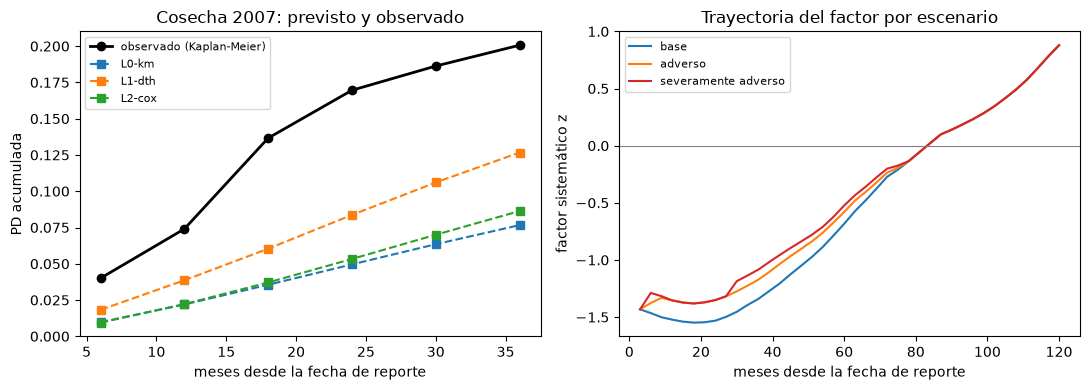

In [9]:
# Dibujar la cosecha de la crisis frente a los tres peldaños y las trayectorias del factor de los tres escenarios
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
months7, obs7, pred7 = curves["2007"]
left.plot(months7, obs7, color="black", marker="o", linewidth=2, label="observado (Kaplan-Meier)")
for rung, color in (("L0-km", "tab:blue"), ("L1-dth", "tab:orange"), ("L2-cox", "tab:green")):
    left.plot(months7, pred7[rung], color=color, marker="s", linestyle="--", label=rung)
left.set_xlabel("meses desde la fecha de reporte")
left.set_ylabel("PD acumulada")
left.set_title("Cosecha 2007: previsto y observado")
left.legend(fontsize=8)

names = {"baseline": "base", "adverse": "adverso", "severely-adverse": "severamente adverso"}
for sid, color in (("baseline", "tab:blue"), ("adverse", "tab:orange"), ("severely-adverse", "tab:red")):
    right.plot(months_path, paths[sid], color=color, label=names[sid])
right.axhline(0.0, color="grey", linewidth=0.8)
right.set_xlabel("meses desde la fecha de reporte")
right.set_ylabel("factor sistemático z")
right.set_title("Trayectoria del factor por escenario")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **El logit en tiempo discreto y el modelo de Cox coinciden de cerca, no idénticamente.** En las 18 covariables compartidas la correlación de los coeficientes es 0,9998 y la mayor diferencia absoluta es 0,0389 (alojamiento y comida, 0,6726 frente a 0,6336). El efecto del plazo, el más fuerte, es $-2{,}4475$ frente a $-2{,}4413$ para préstamos de más de 20 años. La mayor diferencia es de 3,2 errores estándar de L1 (la marca de rotativo, 0,5083 frente a 0,5436): las dos escalas difieren más donde el hazard por período es mayor, como dice la aproximación $\mathrm{logit}\,h \approx \log h$.
- **Un signo macro está equivocado.** El crecimiento del PIB real baja el hazard como se espera ($-0{,}1920$, $z = -49{,}11$, una razón de riesgo de 0,825 por desviación estándar) y la tasa prime lo sube (+0,1138, $z = +18{,}86$, 1,120). La tasa de desempleo lo baja ($-0{,}0534$, $z = -5{,}99$, 0,948), lo opuesto al signo esperado y estadísticamente distinto de cero. Es la sensibilidad que el hallazgo versionado `F-SCENARIO-ORDER` culpa de que el escenario severamente adverso dé una PCE menor que el base (cuaderno 03). Un validador rechaza un coeficiente macro de signo equivocado aunque sea significativo, porque un efecto significativo que se mueve contra la economía puede ser señal de colinealidad entre las variables macro en una historia corta (no se prueba aquí).
- **L1 gana todas las columnas de la comparación.** Su concordancia es 0,6106 frente a 0,5903 del peldaño de Cox (el de Kaplan-Meier no reporta ninguna), su puntaje de Brier integrado es 0,0606 frente a 0,0615 de los otros dos (los tres están a menos de 0,001) y su diferencia de calibración a 12 meses es 0,0025 frente a 0,0118 y 0,0141. Una concordancia cercana a 0,6 es modesta: las covariables del préstamo ordenan los préstamos solo un poco mejor que el azar.
- **Los tres subestiman, y la cosecha de la crisis más.** En la cohorte agrupada el incumplimiento acumulado observado es 0,0324, 0,0804 y 0,1083 a 12, 24 y 36 meses; L1 prevé 0,0298, 0,0637 y 0,0959, y L0 y L2 prevén 0,0205, 0,0438, 0,0656 y 0,0183, 0,0416, 0,0656. A 36 meses la diferencia con signo es 0,0124 para L1 y 0,0427 para los otros dos. Para la cosecha 2007 los valores observados son 0,0740, 0,1696 y 0,2006 y L1 prevé 0,0386, 0,0837 y 0,1267 (una diferencia de 0,0740 a 36 meses), L0 0,0766 (0,1240) y L2 0,0863 (0,1143). Los tres peldaños subestiman en todos los horizontes en ambas cohortes. Las covariables macro de L1 reducen la diferencia y no la cierran.
- **Censura frente a una salida competitiva.** La línea base de Kaplan-Meier da un incumplimiento acumulado de 0,04394 a 36 meses. Con un hazard de prepago declarado de 0,5 %, 1 % y 2 % por trimestre la incidencia de incumplimiento es 0,04222, 0,04056 y 0,03744, así que la mirada de censura queda 4,1 %, 8,3 % y 17,4 % sobre ella a 36 meses, y 9,2 %, 19,2 % y 41,1 % sobre ella a 120 meses. Mientras más largo el horizonte, más importa la elección; la PCE de vida completa del C06 lleva la mirada de censura.
- **El satélite tiene los signos esperados, las trayectorias revierten, y el orden está invertido.** El factor baja con el desempleo ($-1{,}0554$) y la tasa prime ($-1{,}4056$) y sube con el crecimiento (+0,3289). La historia del factor en 63 trimestres tiene una media de $-0{,}150$ y una desviación estándar de 0,731, y termina en $-1{,}80$. Las tres trayectorias de escenario parten en $-1{,}432$ y terminan en $+0{,}879$, que es la reversión al largo plazo. En medio la base queda bajo la adversa y la severamente adversa (en el mes 42, $-1{,}205$, $-1{,}035$ y $-0{,}956$), lo inverso del orden de severidad esperado. En el hazard la tasa de desempleo baja la PD; en el satélite baja el factor, lo que sube la PD: las dos capas discrepan en el signo, y el archivo no dice por qué.

Lo que este cuaderno no muestra: lee los ajustes y no los reajusta, porque el archivo crudo de préstamos no está versionado. Los métodos mixture cure, bosques de supervivencia, supervivencia profunda, edad-período-cohorte y multiestado del estado del arte no los corre el producto, y si hay un paquete disponible para ellos NO ESTÁ VERIFICADO. Los hazards de prepago son insumos de la lección, no estimaciones, y los resultados observados son castigos de préstamos de la SBA.

## Resumen

- Los tres peldaños del C06 son los métodos de supervivencia que recomienda la investigación en su forma más simple: la curva de Kaplan-Meier, un logit en tiempo discreto con covariables macro y un modelo de Cox sin covariables que varíen en el tiempo; los métodos mixture cure, de bosques, profundos y multiestado no se corren.
- El logit y los coeficientes de Cox coinciden de cerca en las covariables comunes, porque el hazard por período es pequeño.
- La capa macro es donde los peldaños difieren y donde el modelo falla la verificación de signos de un validador: el desempleo tiene el signo equivocado en el hazard, lo que invierte el orden de los escenarios.
- El peldaño de hazard gana en discriminación, puntaje de Brier y calibración a 12 meses, pero todo peldaño subestima la PD acumulada en todos los horizontes, y la cosecha de la crisis más.
- Tratar el prepago como censura sobrestima la incidencia de incumplimiento de vida completa, más en horizontes más largos; las trayectorias macro revierten al largo plazo como pide la carta del BCE.

**Qué probar a continuación.** Cambia `EXPECTED_SIGN` y mira qué coeficientes fallan; suma un hazard de prepago de 3 % a la celda de riesgos competitivos; lee las mismas tablas en el archivo `models-rd-2020-06.json` y compara los signos. Después sigue con el cuaderno 08, que demuestra la afirmación de este tema.

## Referencias

- Botha, A. y Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, ecuaciones 6 a 10. https://arxiv.org/abs/2507.15441
- Botha, A., Verster, T. y Breedt, R. (2025), Modelling the term-structure of default risk under IFRS 9 within a multistate regression framework. https://arxiv.org/abs/2502.14479
- Shumway, T. (2001), Forecasting bankruptcy more accurately: a simple hazard model, Journal of Business 74(1), 101-124. https://doi.org/10.1086/209665
- Cox, D. R. (1972), Regression models and life-tables, Journal of the Royal Statistical Society B 34(2), 187-202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- Fine, J. P. y Gray, R. J. (1999), A proportional hazards model for the subdistribution of a competing risk, Journal of the American Statistical Association 94(446), 496-509. https://doi.org/10.1080/01621459.1999.10474144
- Breeden, J. L. (2016), Incorporating lifecycle and environment in loan-level forecasts and stress tests, European Journal of Operational Research 255(2), 649-658. https://doi.org/10.1016/j.ejor.2016.06.008
- ECB Banking Supervision (2020), IFRS 9 in the context of the coronavirus (COVID-19) pandemic, carta a los bancos del 1 de abril de 2020: ponderación de los pronósticos de corto plazo y reversión a valores de largo plazo. https://www.bankingsupervision.europa.eu/press/letterstobanks/shared/pdf/2020/ssm.2020_letter_IFRS_9_in_the_context_of_the_coronavirus_COVID-19_pandemic~4cab8e5650.en.pdf
- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm